# AQI (Envisoft) — Data Quality Report

Per-station hourly PM2.5 at `/home/slow_data/Air_Quality/AQI/process/` — output of `filter_aqi.py` (QC: bad station-months, partially-broken station-days, stuck runs, [3, 350], periods not tracking neighbours). Each section answers one question; figures render inline and save to `pm25_map/aqi/figures/`.

Sections:
1. Dataset overview
2. Null characteristics
3. Spatial distribution
4. Temporal patterns of PM2.5 (daily / diurnal / monthly / seasonal / annual, by region)
5. Other pollutants — null rates & distributions


## 0. Setup

In [1]:
%matplotlib inline
%run _aqi_common.py

ensure_fig_dir()
print('Figures will be saved under:', FIG_DIR)

data, meta = load_all_stations()
print(f'Stations loaded : {meta.shape[0]}')
print(f'Total rows      : {len(data):,}')
print(f'Time span       : {data["timestamp"].min()} → {data["timestamp"].max()}')

Figures will be saved under: /home/work1/projects/Air_Quality/pm25_map/features/aqi/figures
Stations loaded : 106
Total rows      : 1,212,447
Time span       : 2020-01-01 01:00:00 → 2026-06-19 23:00:00


## 1. Dataset overview

### 1.a Per-station record counts & spans
Top 10 by total rows (after dropping rows with no valid timestamp).

In [2]:
(meta[['station','region','rows','valid_PM25','n_days',       'span_days','day_coverage','start','end']]
      .sort_values('valid_PM25', ascending=True)
      .head(10))

,station,region,rows,valid_PM25,n_days,span_days,day_coverage,start,end
40,Hà Nội: UBND xã Ngọc Liệp (LCS),RRD,15,15,1,1,1.000000,2025-10-28 00:00:00,2025-10-28 14:00:00
63,Hải Phòng: Phòng bảo vệ trường mầm non Gia Đức...,RRD,424,424,21,21,1.000000,2025-10-28 16:00:00,2025-11-17 10:00:00
47,"Hà Nội:TT Quan trắc môi trường miền Bắc, 556 N...",RRD,1013,1013,44,44,1.000000,2025-10-28 00:00:00,2025-12-10 09:00:00
19,Hà Nội: Ban chỉ huy Quân sự xã Phúc Thọ(LCS),RRD,1073,1073,48,49,0.979592,2025-10-28 00:00:00,2025-12-15 15:00:00
80,Ninh Bình: UBND Phường Hà Nam (LCS),RRD,1076,1076,46,46,1.000000,2025-10-28 13:00:00,2025-12-12 22:00:00
77,Nam Định: Đường Trần Huy Liệu - P. Trường Thi ...,RRD,2078,2078,92,102,0.901961,2025-08-06 10:00:00,2025-11-15 00:00:00
3,Bắc Giang: Số 1 đ. Hùng Vương - P. Lê Lợi - TP...,NE,2168,2168,102,270,0.377778,2025-05-12 00:00:00,2026-02-05 10:00:00
64,Hải Phòng: Phòng kinh tế môi trường - Ủy ban p...,RRD,2642,2642,114,115,0.991304,2025-10-28 13:00:00,2026-02-19 09:00:00
48,Hưng Yên: Cổng bảo vệ ủy ban xã Như Quỳnh (LCS),RRD,2735,2735,119,169,0.704142,2025-10-28 13:00:00,2026-04-14 23:00:00
96,Thái Nguyên: Trung Tâm Hành Chính Công Xã Đồng...,NE,2829,2829,124,137,0.905109,2026-01-19 00:00:00,2026-06-04 22:00:00


### 1.b Row-count distribution
Stations bunch into two cohorts: ~5k rows (~7 months, newer deploys) and ~21–28k rows (~2.5–3.5 years). A few stations have <2k rows.

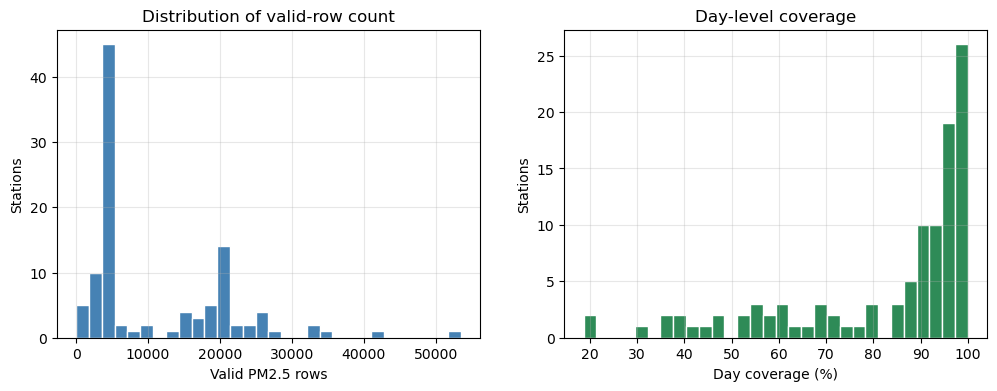

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(meta['valid_PM25'], bins=30, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Valid PM2.5 rows'); axes[0].set_ylabel('Stations')
axes[0].set_title('Distribution of valid-row count')
axes[0].grid(alpha=0.3)
axes[1].hist(meta['day_coverage']*100, bins=30, color='seagreen', edgecolor='white')
axes[1].set_xlabel('Day coverage (%)'); axes[1].set_ylabel('Stations')
axes[1].set_title('Day-level coverage')
axes[1].grid(alpha=0.3)
save_fig('01b_row_count_and_coverage'); plt.show()

### 1.c Stations per region
Counts come from `Masterdata/envisoft_station_map.csv` (region column).

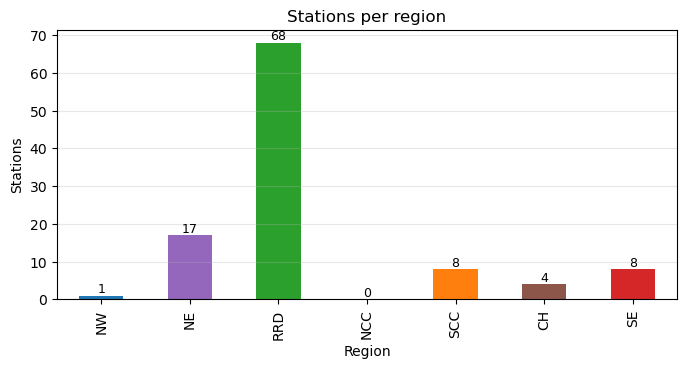

,n_stations
region,
NW,1
NE,17
RRD,68
NCC,0
SCC,8
CH,4
SE,8


In [4]:
by_region = (meta[meta['region']!='UNKNOWN']
             .groupby('region', observed=True).size()
             .reindex(REGION_ORDER, fill_value=0))
fig, ax = plt.subplots(figsize=(8, 3.5))
by_region.plot(kind='bar', color=[REGION_COLORS[r] for r in by_region.index], ax=ax)
ax.set_ylabel('Stations'); ax.set_xlabel('Region'); ax.set_title('Stations per region')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
ax.grid(alpha=0.3, axis='y')
save_fig('01c_stations_per_region'); plt.show()
by_region.to_frame('n_stations')

In [5]:
# ### 1.d Per-station PM2.5 statistics
# min / max / mean / std cho từng trạm. Bảng sort theo region rồi mean giảm dần.
stats = (data.dropna(subset=[PRIMARY])
              .groupby(['station', 'region'], observed=True)[PRIMARY]
              .agg(n='size',
                   min='min', max='max',
                   mean='mean', std='std',
                   p50='median', p95=lambda s: s.quantile(0.95))
              .round(2)
              .reset_index()
              .sort_values(['region', 'n'], ascending=[True, False]))

print(f"Per-station PM2.5 stats — {len(stats)} trạm")
# Hiển thị toàn bộ (không truncate)
with pd.option_context('display.max_rows', None, 'display.width', None):
    display(stats)

# Cũng save ra CSV để tiện copy vào báo cáo
out_csv = FIG_DIR / 'per_station_pm25_stats.csv'
stats.to_csv(out_csv, index=False)
print(f"Saved → {out_csv}")


Per-station PM2.5 stats — 106 trạm


,station,region,n,min,max,mean,std,p50,p95
13,Gia Lai: UBND thị xã An Khê (KK),CH,24303,3.00,342.38,12.69,10.17,10.01,29.52
12,Gia Lai: KCN Trà Đa - Tp Pleiku (KK),CH,22363,3.00,239.36,16.05,14.85,11.44,42.59
72,Lâm Đồng: Vườn hoa - đối diện THCS Lam Sơn - P...,CH,15684,3.00,235.27,22.16,21.27,15.02,63.61
14,Gia lai: Chư Sê (KK),CH,10315,3.00,227.52,14.31,11.64,10.81,34.65
83,Phú Thọ: đường Hùng Vương - Tp Việt Trì (KK),NE,42480,3.00,290.65,24.60,19.34,18.72,64.79
91,Quảng Ninh: UBND TP Uông Bí (KK),NE,26325,3.00,117.55,13.85,9.37,11.59,30.08
86,Quảng Ninh: Gần KCN Cái Lân (KK),NE,24288,3.00,208.93,13.28,11.73,9.89,34.41
87,Quảng Ninh: Km11 - Minh Thành (KK),NE,22338,3.00,162.02,13.92,12.11,10.06,37.29
89,Quảng Ninh: Nhà máy tuyển than Nam Cầu Trắng -...,NE,18472,3.00,93.76,11.51,7.81,9.17,25.86
93,Quảng Ninh: UBND phường Mạo Khê - Đông Triều (KK),NE,18361,3.00,215.54,15.04,11.79,11.78,36.46


Saved → /home/work1/projects/Air_Quality/pm25_map/features/aqi/figures/per_station_pm25_stats.csv


## 2. Null characteristics

### 2.a Overall null rate per pollutant
Network-wide (all stations pooled). Tells us which channels are dense and which are sparse / mostly absent.

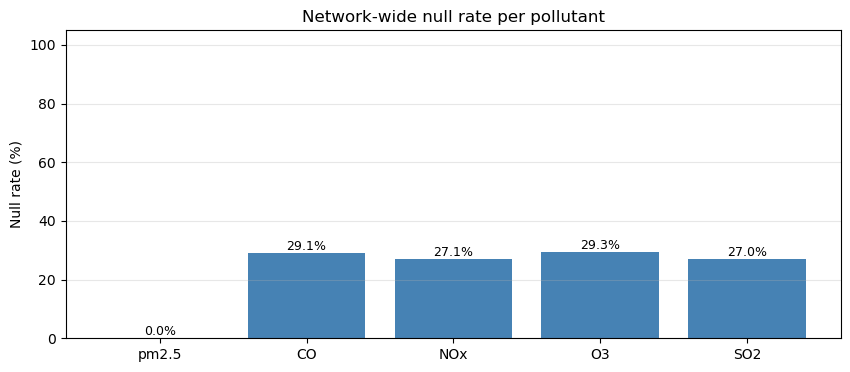

,null_pct
pm2.5,0.00
CO,29.10
NOx,27.11
O3,29.32
SO2,26.98


In [6]:
null_pct = (1 - data[POLLUTANTS].notna().mean()) * 100
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(null_pct.index, null_pct.values,
              color=['firebrick' if v > 50 else 'steelblue' for v in null_pct])
for b, v in zip(bars, null_pct.values):
    ax.annotate(f'{v:.1f}%', (b.get_x()+b.get_width()/2, v),
                ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Null rate (%)'); ax.set_ylim(0, 105)
ax.set_title('Network-wide null rate per pollutant'); ax.grid(alpha=0.3, axis='y')
save_fig('02a_null_rate_overall'); plt.show()
null_pct.round(2).to_frame('null_pct')

### 2.c PM2.5 day-level coverage map
How many calendar days inside each station's span actually carry ≥ 1 valid PM2.5 record? This is the meaningful gap measure for hourly products.

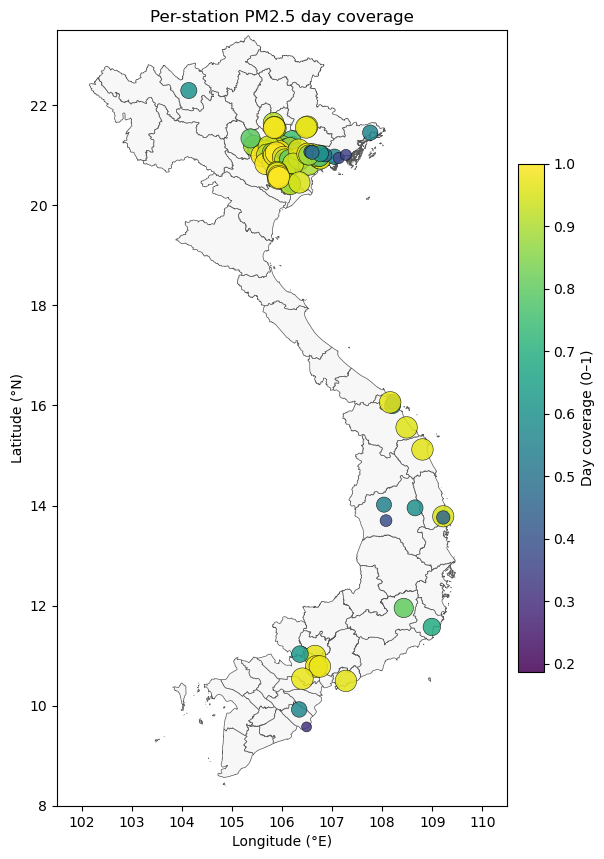

In [7]:
fig, ax = plt.subplots(figsize=(7, 11))
plot_stations_on_vn(meta, value_col='day_coverage', ax=ax,
                    cmap='viridis', title='Per-station PM2.5 day coverage',
                    cbar_label='Day coverage (0–1)')
save_fig('02c_map_pm25_day_coverage'); plt.show()

## 3. Spatial distribution

### 3.a Stations colored by region
Sanity check on the regional grouping used in every later plot.

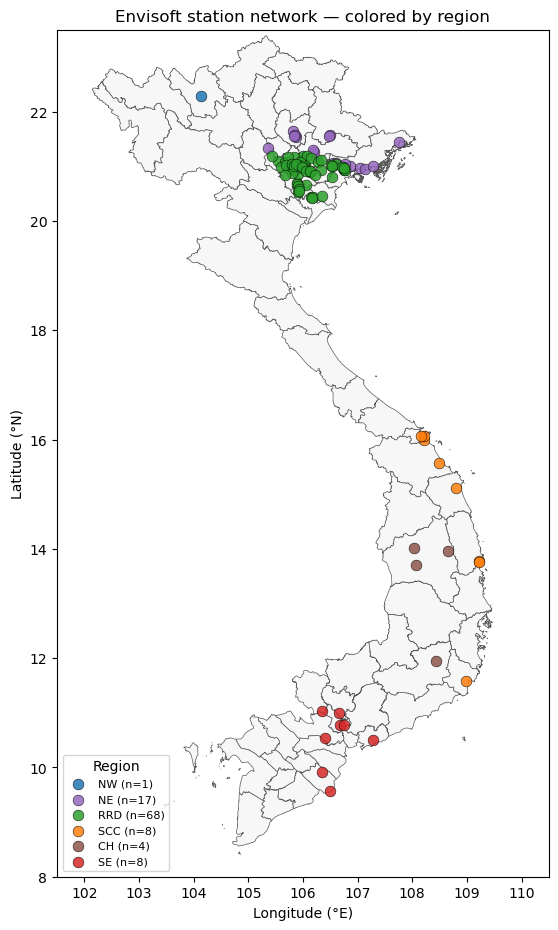

In [8]:
fig, ax = plt.subplots(figsize=(7, 11)); vn_basemap(ax=ax)
for region in REGION_ORDER:
    sub = meta[meta['region']==region]
    if sub.empty: continue
    ax.scatter(sub['lon'], sub['lat'], s=60, edgecolor='black',
               linewidth=0.4, color=REGION_COLORS[region],
               label=f'{region} (n={len(sub)})', alpha=0.85)
ax.legend(loc='lower left', fontsize=8, title='Region')
ax.set_title('Envisoft station network — colored by region')
save_fig('03a_map_stations_by_region'); plt.show()

### 3.b Mean PM2.5 per station

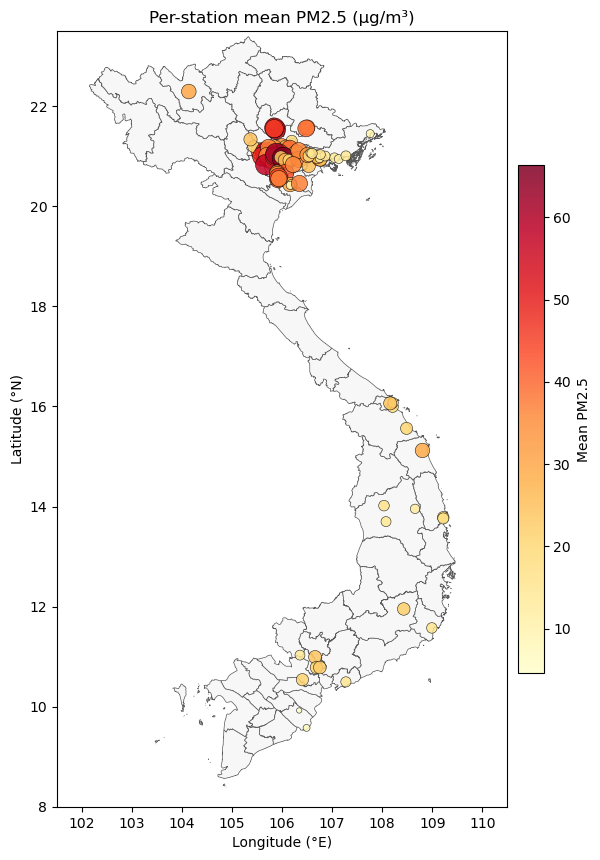

In [9]:
fig, ax = plt.subplots(figsize=(7, 11))
plot_stations_on_vn(meta, value_col='mean_PM25', ax=ax, cmap='YlOrRd',
                    title='Per-station mean PM2.5 (µg/m³)',
                    cbar_label='Mean PM2.5')
save_fig('03b_map_mean_pm25'); plt.show()

### 3.c 95th-percentile PM2.5 per station (pollution hotspots)

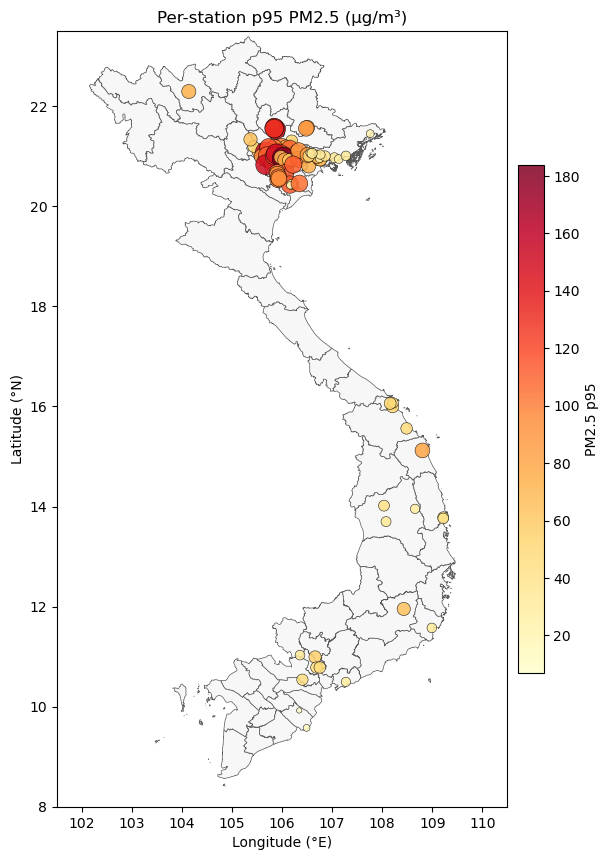

In [10]:
fig, ax = plt.subplots(figsize=(7, 11))
plot_stations_on_vn(meta, value_col='p95_PM25', ax=ax, cmap='YlOrRd',
                    title='Per-station p95 PM2.5 (µg/m³)',
                    cbar_label='PM2.5 p95')
save_fig('03c_map_p95_pm25'); plt.show()

## 4. Temporal patterns of PM2.5

All figures use the network frame `data`; region is the master-CSV region column.

### 4.a Daily mean PM2.5 with cross-station IQR
Heavy line = daily mean of all stations; band = 25–75 percentile across stations.

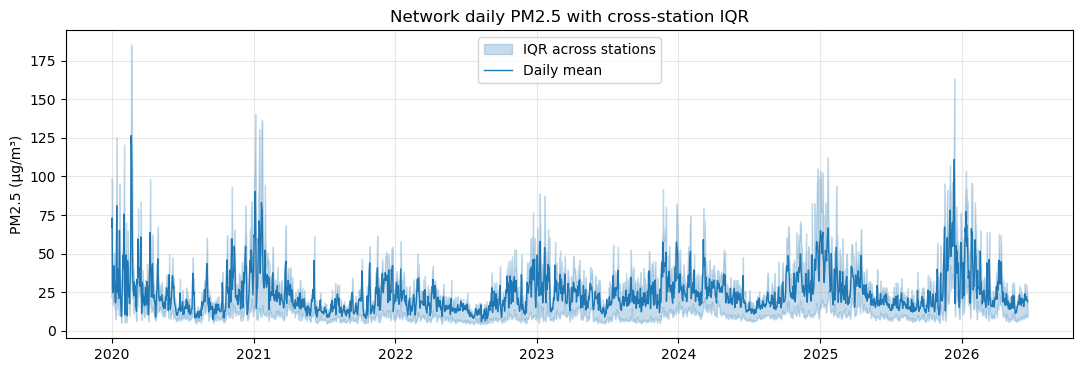

In [11]:
d = data.set_index('timestamp')[PRIMARY]
by_day = d.groupby(pd.Grouper(freq='D'))
mean = by_day.mean(); q25 = by_day.quantile(0.25); q75 = by_day.quantile(0.75)
fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(mean.index, q25, q75, alpha=0.25, color='tab:blue', label='IQR across stations')
ax.plot(mean.index, mean.values, lw=1, color='tab:blue', label='Daily mean')
ax.set_ylabel('PM2.5 (µg/m³)'); ax.set_title('Network daily PM2.5 with cross-station IQR')
ax.legend(); ax.grid(alpha=0.3)
save_fig('04a_daily_network_timeseries'); plt.show()

### 4.b Diurnal cycle by region
Mean PM2.5 by hour-of-day, split by region.

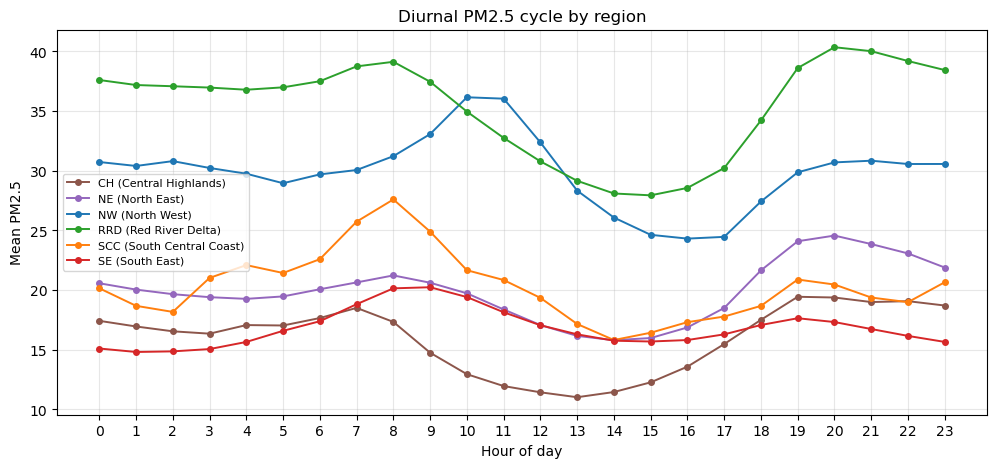

In [12]:
d = data[data['region'].isin(REGION_ORDER)]
diurnal = d.groupby(['region','hour'], observed=True)[PRIMARY].mean().reset_index()
fig, ax = plt.subplots(figsize=(12, 5))
for region, sub in diurnal.groupby('region', observed=True):
    ax.plot(sub['hour'], sub[PRIMARY], '-o', ms=4, lw=1.4,
            label=f'{region} ({REGION_FULL_NAMES[region]})',
            color=REGION_COLORS[region])
ax.set_xticks(range(0, 24)); ax.set_xlabel('Hour of day'); ax.set_ylabel('Mean PM2.5')
ax.set_title('Diurnal PM2.5 cycle by region'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
save_fig('04b_diurnal_by_region'); plt.show()

### 4.c Diurnal × seasonal heatmap (network mean)
Where the diurnal cycle differs between dry/wet seasons.

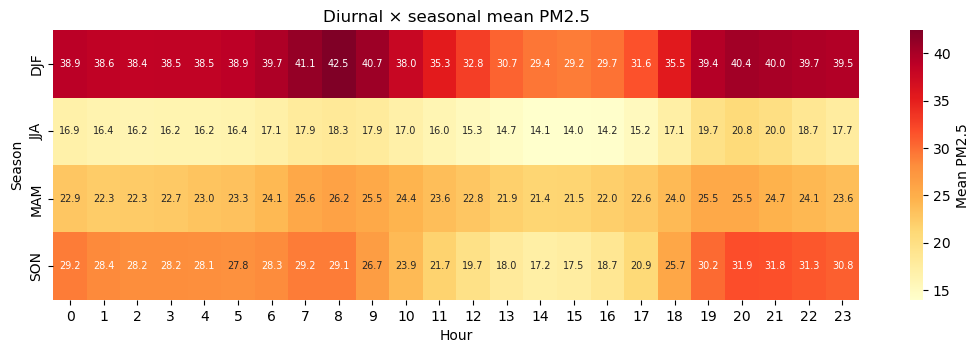

In [13]:
idx = pd.MultiIndex.from_product([SEASON_ORDER, range(24)], names=['season','hour'])
pivot = (data.groupby(['season','hour'], observed=True)[PRIMARY]
             .mean().reindex(idx).unstack('hour'))
fig, ax = plt.subplots(figsize=(13, 3.5))
sns.heatmap(pivot, cmap='YlOrRd', cbar_kws={'label': 'Mean PM2.5'},
            ax=ax, annot=True, fmt='.1f', annot_kws={'size': 7})
ax.set_title('Diurnal × seasonal mean PM2.5'); ax.set_xlabel('Hour'); ax.set_ylabel('Season')
save_fig('04c_diurnal_seasonal_heatmap'); plt.show()

### 4.d Monthly climatology by region

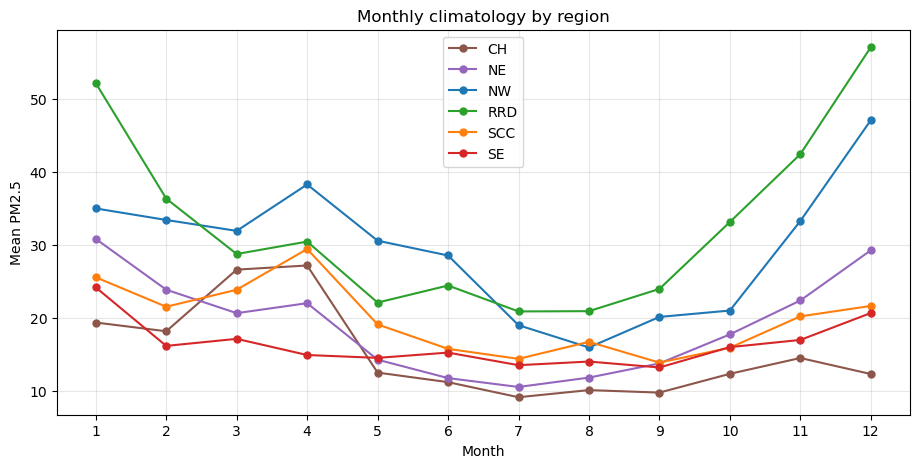

In [14]:
d = data[data['region'].isin(REGION_ORDER)]
mc = d.groupby(['region','month'], observed=True)[PRIMARY].mean().reset_index()
fig, ax = plt.subplots(figsize=(11, 5))
for region, sub in mc.groupby('region', observed=True):
    ax.plot(sub['month'], sub[PRIMARY], '-o', ms=5, lw=1.5,
            label=region, color=REGION_COLORS[region])
ax.set_xticks(range(1, 13)); ax.set_xlabel('Month'); ax.set_ylabel('Mean PM2.5')
ax.set_title('Monthly climatology by region'); ax.legend(); ax.grid(alpha=0.3)
save_fig('04d_monthly_climatology_by_region'); plt.show()

### 4.e Seasonal distribution by region (boxplot)

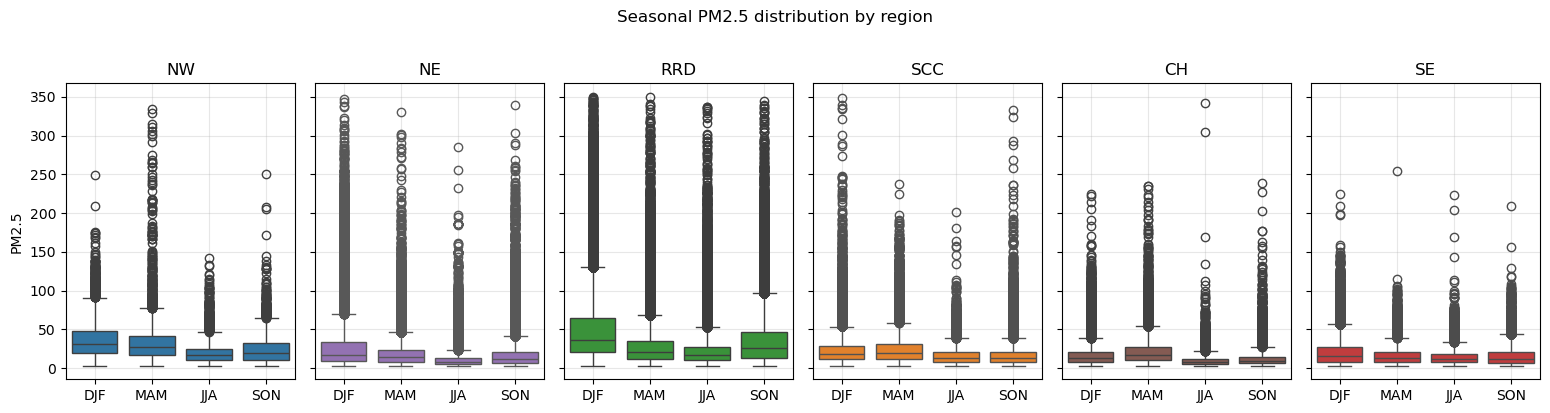

In [15]:
d = data[data['region'].isin(REGION_ORDER)].copy()
d['season'] = pd.Categorical(d['season'], categories=SEASON_ORDER)
regions = [r for r in REGION_ORDER if r in d['region'].unique()]
fig, axes = plt.subplots(1, len(regions), figsize=(2.6*len(regions), 4), sharey=True)
if len(regions) == 1: axes = [axes]
for ax, region in zip(axes, regions):
    sub = d[d['region']==region]
    sns.boxplot(data=sub, x='season', y=PRIMARY, order=SEASON_ORDER,
                ax=ax, color=REGION_COLORS[region], showfliers=True)
    ax.set_title(region); ax.set_xlabel(''); ax.grid(alpha=0.3)
    ax.set_ylabel('PM2.5' if ax is axes[0] else '')
fig.suptitle('Seasonal PM2.5 distribution by region', y=1.02)
save_fig('04e_seasonal_boxplot_by_region'); plt.tight_layout(); plt.show()

### 4.f Annual mean by year × region

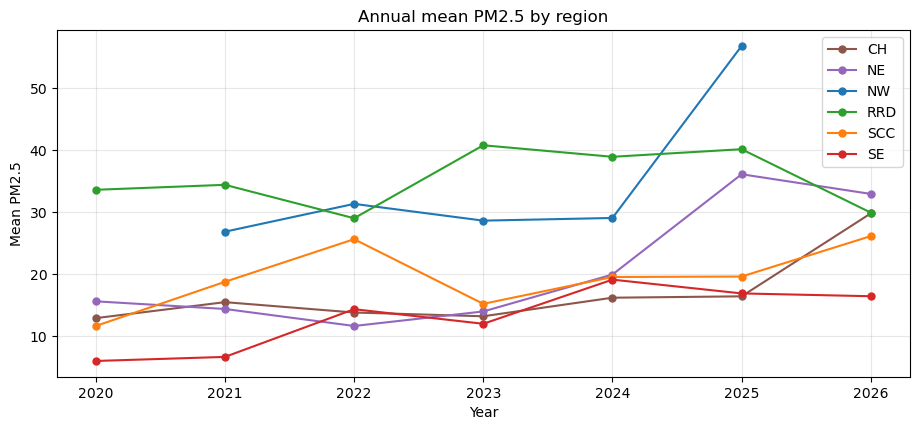

In [16]:
d = data[data['region'].isin(REGION_ORDER)]
yr = d.groupby(['year','region'], observed=True)[PRIMARY].mean().reset_index()
fig, ax = plt.subplots(figsize=(11, 4.5))
for region, sub in yr.groupby('region', observed=True):
    ax.plot(sub['year'], sub[PRIMARY], '-o', ms=5, lw=1.5,
            label=region, color=REGION_COLORS[region])
ax.set_xlabel('Year'); ax.set_ylabel('Mean PM2.5'); ax.set_title('Annual mean PM2.5 by region')
ax.legend(); ax.grid(alpha=0.3)
save_fig('04f_annual_by_region'); plt.show()

### 4.g Region-aggregated monthly time series

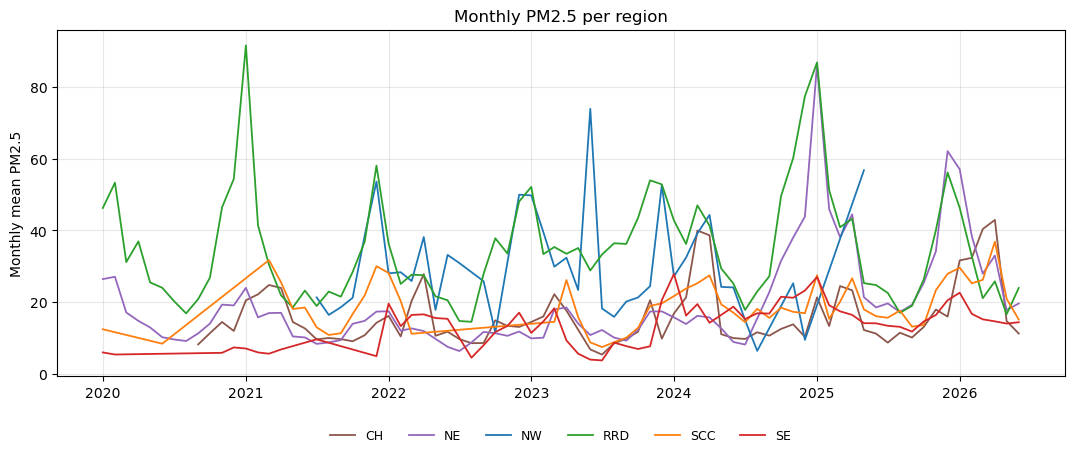

In [17]:
d = data[data['region'].isin(REGION_ORDER)]
mr = (d.set_index('timestamp')
        .groupby(['region', pd.Grouper(freq='MS')], observed=True)[PRIMARY]
        .mean().reset_index())
fig, ax = plt.subplots(figsize=(13, 4.5))
for region, sub in mr.groupby('region', observed=True):
    ax.plot(sub['timestamp'], sub[PRIMARY], '-', lw=1.3,
            label=region, color=REGION_COLORS[region])
ax.set_ylabel('Monthly mean PM2.5'); ax.set_title('Monthly PM2.5 per region')
ax.grid(alpha=0.3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12),
          ncol=len(REGION_ORDER), fontsize=9, frameon=False)
save_fig('04g_region_monthly_timeseries'); plt.show()


## 5. Other pollutants

Same dataset, focused on the gases + particulates beside PM2.5: PM1, PM10, CO, NO, NO2, NOx, O3, SO2, TVOC.

### 5.a Per-station null rate per pollutant (excluding PM2.5)
How many stations actually have data for each gas? `100%` cells mean the station never recorded that channel.

In [18]:
others = [c for c in POLLUTANTS if c != PRIMARY]
null_mat = per_station_null_pct(data, others)
summary = null_mat.describe(percentiles=[.25,.5,.75]).T.round(1)
summary['n_stations_with_any_data'] = (null_mat < 100).sum(axis=0).values
summary[['n_stations_with_any_data', 'mean', '25%', '50%', '75%']]

,n_stations_with_any_data,mean,25%,50%,75%
CO,52,56.9,5.7,100.0,100.0
NOx,47,58.5,1.1,100.0,100.0
O3,51,56.8,6.6,100.0,100.0
SO2,52,55.6,7.5,100.0,100.0


### 5.b Coverage fraction per pollutant (non-null share)
Compact bar chart — easier to scan than the heatmap when prioritising which channels to model.

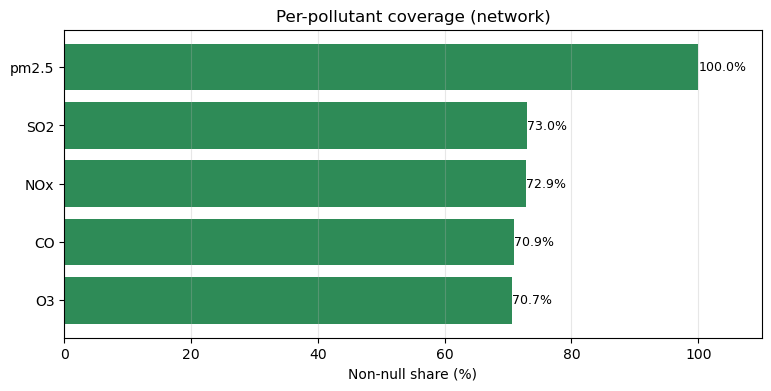

In [19]:
cov = data[POLLUTANTS].notna().mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(cov.index, cov.values*100,
               color=['firebrick' if v < 0.5 else 'seagreen' for v in cov])
for b, v in zip(bars, cov.values):
    ax.annotate(f'{v*100:.1f}%', (v*100, b.get_y()+b.get_height()/2),
                ha='left', va='center', fontsize=9)
ax.set_xlim(0, 110); ax.set_xlabel('Non-null share (%)')
ax.set_title('Per-pollutant coverage (network)'); ax.grid(alpha=0.3, axis='x')
save_fig('05b_pollutant_coverage'); plt.show()

### 5.c Distribution per pollutant (clipped at p99, log y)
Heavy tails are typical — a log y-axis keeps the bulk visible.

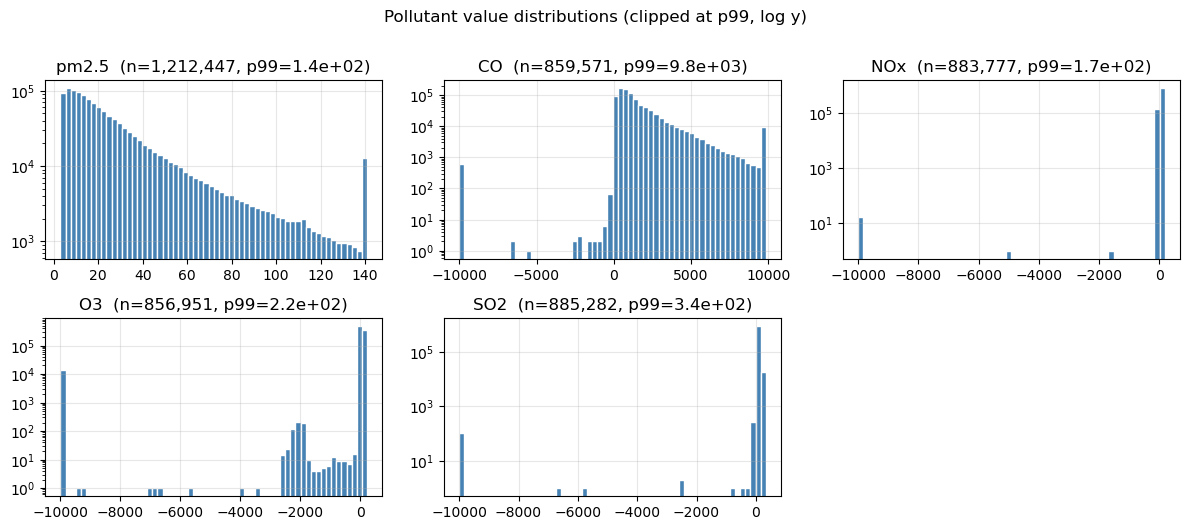

In [20]:
ncols = 3; nrows = -(-len(POLLUTANTS)//ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.0*ncols, 2.6*nrows))
axes = axes.ravel()
for ax, col in zip(axes, POLLUTANTS):
    v = data[col].dropna()
    if v.empty:
        ax.set_title(f'{col} — no data'); ax.set_axis_off(); continue
    clip = v.quantile(0.99)
    ax.hist(v.clip(upper=clip), bins=60, color='steelblue', edgecolor='white')
    ax.set_yscale('log')
    ax.set_title(f'{col}  (n={len(v):,}, p99={clip:.2g})')
    ax.grid(alpha=0.3)
for ax in axes[len(POLLUTANTS):]: ax.set_axis_off()
fig.suptitle('Pollutant value distributions (clipped at p99, log y)', y=1.01)
save_fig('05c_pollutant_distributions'); plt.tight_layout(); plt.show()

### 5.d Numeric summary per pollutant
Combined null/coverage + value statistics for export.

In [21]:
rows = []
for col in POLLUTANTS:
    v = data[col]
    nn = v.dropna()
    rows.append(dict(
        pollutant=col,
        n_valid=int(nn.shape[0]),
        null_pct=round(100*(1-v.notna().mean()), 2),
        mean=float(nn.mean())   if len(nn) else float('nan'),
        median=float(nn.median()) if len(nn) else float('nan'),
        p95=float(nn.quantile(0.95)) if len(nn) else float('nan'),
        max=float(nn.max())     if len(nn) else float('nan'),
    ))
summary = pd.DataFrame(rows).set_index('pollutant').round(2)
summary

,n_valid,null_pct,mean,median,p95,max
pollutant,,,,,,
pm2.5,1212447,0.00,2.690000e+01,18.05,80.87,3.500000e+02
CO,859571,29.10,4.725440e+03,947.49,4690.10,2.188798e+09
NOx,883777,27.11,2.528683e+08,16.91,77.71,2.234787e+14
O3,856951,29.32,-1.089300e+02,38.15,133.84,1.525793e+04
SO2,885282,26.98,2.564000e+01,10.90,90.61,3.298860e+03


## Notes

- Source CSVs: `/home/slow_data/Air_Quality/AQI/process/` (106 stations after QC v3 and the station exclusion list, rerun 23/10/2026).
- Region codes follow `Masterdata/envisoft_station_map.csv` (NW, NE, RRD, NCC, SCC, CH, SE).
- Figures are written to `pm25_map/aqi/figures/` and rendered inline (the helper
  `save_fig` does **not** call `plt.close`).
- For the QC filters and the problem each one solves see
  [`filter_aqi.py`](filter_aqi.py).
